# Import packages

In [2]:
import pandas as pd
import geopandas as gpd
from shapely.geometry import Point

import isodate
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import calendar
from pathlib import Path

# Read data

## Read nbt-related YouTube data

In [ ]:
videos_info_finland = pd.read_csv('data/videos_info_finland_all.csv')
videos_info_finland_geotagged = videos_info_finland[~videos_info_finland['latitude'].isnull()]
print(f'videos_info_finland.shape: {videos_info_finland.shape}')
print(f'videos_info_finland_geotagged.shape: {videos_info_finland_geotagged.shape}')

(195228, 32)

In [ ]:
# Read nbt_identification pickle files and combine them
data_dir = Path('.')
files = sorted(data_dir.glob('data/nbt_identification_files/nbt_identification_qwen3_14b_*.pkl'))

series_list = [pd.read_pickle(f) for f in files]
# ensure each item is a Series
series_list = [s if isinstance(s, pd.Series) else pd.Series(s) for s in series_list]

# Append series preserving original indices
nbt_identification = pd.concat(series_list, axis=0)

# Uniform the answers (case-insensitive); non-matching entries -> NA
nbt_identification = nbt_identification.astype(str).apply(
    lambda x: 'Yes' if 'yes' in x.lower() else ('No' if 'no' in x.lower() else pd.NA)
)
nbt_identification

nbt_identification.to_pickle('data/nbt_identification_qwen3_14b.pkl')

In [ ]:
# Get videos marked as 'Yes'
video_id_nbt_relevant = nbt_identification[nbt_identification['nbt_relevance']=='Yes'].videoo_id.to_list()
nbt_videos = videos_info_finland[videos_info_finland['video_id'].isin(video_id_nbt_relevant)].copy()

# Remove duplicates based on video_id
nbt_videos = nbt_videos.drop_duplicates(subset='video_id').reset_index(drop=True)

nbt_videos.shape

(33334, 32)

In [14]:
# Convert nbt_videos to GeoDataFrame
geometry = [Point(xy) for xy in zip(nbt_videos['longitude'], nbt_videos['latitude'])]

gdf_nbt_videos = gpd.GeoDataFrame(nbt_videos, geometry=geometry, crs='EPSG:4326')

gdf_nbt_videos = gdf_nbt_videos.to_crs(epsg=3067)

## Read boundaries

In [3]:
# Read Finland boundary shapefile
gdf_finland = gpd.read_file('../boundaries/Finland_shapefile/Finland_boundaries.shp')
gdf_finland.crs

<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

In [3]:
# Read state-owned lands boundary
gdf_state_lands = gpd.read_file('../boundaries/MH kiinteistot.gpkg')
gdf_state_lands.crs

<Projected CRS: EPSG:3067>
Name: ETRS89 / TM35FIN(E,N)
Axis Info [cartesian]:
- E[east]: Easting (metre)
- N[north]: Northing (metre)
Area of Use:
- name: Finland - onshore and offshore.
- bounds: (19.08, 58.84, 31.59, 70.09)
Coordinate Operation:
- name: TM35FIN
- method: Transverse Mercator
Datum: European Terrestrial Reference System 1989 ensemble
- Ellipsoid: GRS 1980
- Prime Meridian: Greenwich

<Axes: >

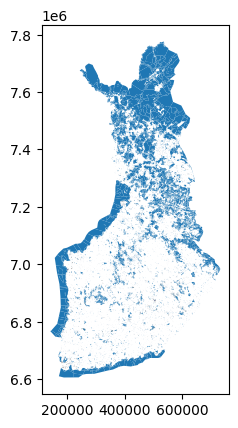

In [4]:
gdf_state_lands.plot()

In [23]:
# Read state-owned nature reserves boundary
gdf_state_nature_reserves = gpd.read_file('../boundaries/luonnonsuojelualueet_valtio/LsAlueValtio.shp')
gdf_state_nature_reserves.crs

<Projected CRS: EPSG:3067>
Name: ETRS89 / TM35FIN(E,N)
Axis Info [cartesian]:
- E[east]: Easting (metre)
- N[north]: Northing (metre)
Area of Use:
- name: Finland - onshore and offshore.
- bounds: (19.08, 58.84, 31.59, 70.09)
Coordinate Operation:
- name: TM35FIN
- method: Transverse Mercator
Datum: European Terrestrial Reference System 1989 ensemble
- Ellipsoid: GRS 1980
- Prime Meridian: Greenwich

In [24]:
# Read national parks boundary
gdf_national_parks = gpd.read_file('../boundaries/finnish_national_parks_syke_2024.gpkg')
gdf_national_parks.crs

<Projected CRS: EPSG:3067>
Name: ETRS89 / TM35FIN(E,N)
Axis Info [cartesian]:
- E[east]: Easting (metre)
- N[north]: Northing (metre)
Area of Use:
- name: Finland - onshore and offshore.
- bounds: (19.08, 58.84, 31.59, 70.09)
Coordinate Operation:
- name: TM35FIN
- method: Transverse Mercator
Datum: European Terrestrial Reference System 1989 ensemble
- Ellipsoid: GRS 1980
- Prime Meridian: Greenwich

In [25]:
# Read wilderness areas boundary
gdf_wilderness = gpd.read_file('../boundaries/luonnonsuojelualueet_eramaa/LsAlueEramaa.shp')
gdf_wilderness.crs

<Projected CRS: EPSG:3067>
Name: ETRS89 / TM35FIN(E,N)
Axis Info [cartesian]:
- E[east]: Easting (metre)
- N[north]: Northing (metre)
Area of Use:
- name: Finland - onshore and offshore.
- bounds: (19.08, 58.84, 31.59, 70.09)
Coordinate Operation:
- name: TM35FIN
- method: Transverse Mercator
Datum: European Terrestrial Reference System 1989 ensemble
- Ellipsoid: GRS 1980
- Prime Meridian: Greenwich

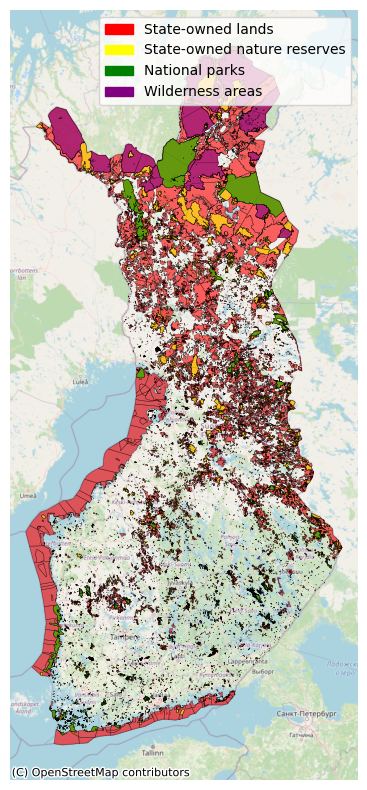

In [30]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import contextily as ctx

# Reproject to Web Mercator if needed
gdf_state_lands_web = gdf_state_lands.to_crs(epsg=3857)
gdf_state_nature_reserves_web = gdf_state_nature_reserves.to_crs(epsg=3857)
gdf_national_parks_web = gdf_national_parks.to_crs(epsg=3857)
gdf_wilderness_web = gdf_wilderness.to_crs(epsg=3857)

fig, ax = plt.subplots(figsize=(10, 10))

# Plot each layer
gdf_state_lands_web.plot(ax=ax, color='red', edgecolor='black', linewidth=0.3, alpha=0.6, zorder=3)
gdf_state_nature_reserves_web.plot(ax=ax, color='yellow', edgecolor='black', linewidth=0.3, alpha=0.6, zorder=3)
gdf_national_parks_web.plot(ax=ax, color='green', edgecolor='black', linewidth=0.3, alpha=0.6, zorder=3)
gdf_wilderness_web.plot(ax=ax, color='purple', edgecolor='black', linewidth=0.3, alpha=0.6, zorder=3)

# Add basemap
ctx.add_basemap(ax, source=ctx.providers.OpenStreetMap.Mapnik, crs=gdf_state_lands_web.crs, zorder=1)

# Create legend handles
red_patch = mpatches.Patch(color='red', label='State-owned lands')
yellow_patch = mpatches.Patch(color='yellow', label='State-owned nature reserves')
green_patch = mpatches.Patch(color='green', label='National parks')
purple_patch = mpatches.Patch(color='purple', label='Wilderness areas')

ax.legend(handles=[red_patch, yellow_patch, green_patch, purple_patch],
          loc='upper right',
          frameon=True)

# ax.set_title("State-Owned Lands, State-owned Nature Reserves, and National Parks")
ax.set_axis_off()

plt.show()



## Read nbt_related YouTube data within boundaries

In [7]:
def spatial_join_videos_with_boundary(gdf_videos, gdf_boundary):
    # Perform spatial join
    gdf_joined = gpd.sjoin(gdf_videos, gdf_boundary, how='inner', predicate='within')
    # Keep only original columns
    gdf_joined = gdf_joined[gdf_videos.columns]

    return gdf_joined

In [31]:
# Spatial join: keep only points that fall within state-owned lands
gdf_videos_state = spatial_join_videos_with_boundary(gdf_nbt_videos, gdf_state_lands)

# Spatial join: keep only points that fall within state-owned nature reserves
gdf_videos_nr = spatial_join_videos_with_boundary(gdf_nbt_videos, gdf_state_nature_reserves)
# Add a column "nature_reserve" to gdf_videos_state
gdf_videos_state['nature_reserve'] = gdf_videos_state['video_id'].isin(gdf_videos_nr['video_id']).astype(int)

# Spatial join: keep only points that fall within national parks
gdf_videos_np = spatial_join_videos_with_boundary(gdf_nbt_videos, gdf_national_parks)
# Add a column "national_park" to gdf_videos_state
gdf_videos_state['national_park'] = gdf_videos_state['video_id'].isin(gdf_videos_np['video_id']).astype(int)

# Spatial join: keep only points that fall within wilderness areas
gdf_videos_wa = spatial_join_videos_with_boundary(gdf_nbt_videos, gdf_wilderness)
# Add a column "wilderness_area" to gdf_videos_state
gdf_videos_state['wilderness_area'] = gdf_videos_state['video_id'].isin(gdf_videos_wa['video_id']).astype(int)

In [16]:
area = 'state-owned lands'
gdf_videos = gdf_videos_state.copy()

# area = 'state-owned nature reserve'
# gdf_videos = gdf_videos[gdf_videos['nature_reserve']==1].copy()
gdf_videos_nr = gdf_videos[gdf_videos['nature_reserve']==1].copy()

# area = 'national park'
# gdf_videos = gdf_videos[gdf_videos['national_park']==1].copy()
gdf_videos_np = gdf_videos[gdf_videos['national_park']==1].copy()

# area = 'wilderness area'
# gdf_videos = gdf_videos[gdf_videos['wilderness_area']==1].copy()
gdf_videos_wa = gdf_videos[gdf_videos['wilderness_area']==1].copy()

# area = 'state-owned commercial forest'
# gdf_videos = gdf_videos[(gdf_videos['nature_reserve']==0) & (gdf_videos['wilderness_area']==0)].copy()
gdf_videos_cf = gdf_videos[(gdf_videos['nature_reserve']==0) & (gdf_videos['wilderness_area']==0)].copy()
# Add a column "commercial_forest" to gdf_videos_state
gdf_videos_state['commercial_forest'] = gdf_videos_state['video_id'].isin(gdf_videos_cf['video_id']).astype(int)

In [11]:
print(f"Number of NBT videos in state-owned nature reserves: {gdf_videos_nr.shape[0]}")
print(f"Number of NBT videos in national parks: {gdf_videos_np.shape[0]}")
print(f"Number of NBT videos in wilderness areas: {gdf_videos_wa.shape[0]}")
print(f"Number of NBT videos in state-owned commercial forests: {gdf_videos_cf.shape[0]}")

Number of NBT videos in state-owned nature reserves: 2916
Number of NBT videos in national parks: 2655
Number of NBT videos in wilderness areas: 566
Number of NBT videos in state-owned commercial forests: 2740


In [ ]:
def preprocess_gdf_videos(gdf_videos):
    # Drop duplicate video_id entries``
    gdf_videos = gdf_videos.drop_duplicates(subset='video_id').reset_index(drop=True)
    # Select relevant columns
    gdf_videos = gdf_videos[['video_id', 'title', 'description', 'channel_id', 'channel_title', 'published_at',
                             'location','category_id', 'topics', 'default_audio_language', 'default_language',
                             'tags', 'comment_count', 'like_count', 'view_count', 'thumbnail_default',
                             'duration', 'nature_reserve', 'national_park', 'wilderness_area', 'geometry']]

    # Get the datetime
    gdf_videos['datetime'] = pd.to_datetime(gdf_videos['published_at'], utc=True)
    gdf_videos['year'] = gdf_videos['datetime'].dt.year
    gdf_videos['month'] = gdf_videos['datetime'].dt.month
    gdf_videos['year_month'] = gdf_videos['datetime'].dt.to_period('M')

    # Convert duration from ISO 8601 to seconds
    gdf_videos['duration_seconds'] = gdf_videos['duration'].apply(lambda x: isodate.parse_duration(x).total_seconds())

    return gdf_videos

In [ ]:
# Preprocess gdf_videos_state
gdf_videos_state = preprocess_gdf_videos(gdf_videos_state)
gdf_videos_state.to_file('../../data/nbt_videos_in_state_owned_lands.gpkg', driver='GPKG')

In [12]:
# Read the geopackage file of nbt_videos_in_state_owned_lands
gdf_videos_state = gpd.read_file('../../data/nbt_videos_in_state_owned_lands.gpkg')

In [4]:
gdf_videos_state.year.value_counts().sort_index()

year
2018     231
2019     413
2020    1102
2021    1420
2022    1269
2023    1895
Name: count, dtype: int64